# Semi-coherent EMRI search (Speri, Tenorio, Chapman-Bird & Gerosa 2026) on LISA Analysis Tools

This notebook runs the single-harmonic semi-coherent search of
[arXiv:2510.20891](https://arxiv.org/abs/2510.20891)
(code: [github.com/lorenzosp/EMRI-Search](https://github.com/lorenzosp/EMRI-Search))
with the modular re-implementation in `lisatools.search.emri`.

**Pipeline**

1. **Inject** a FEW Kerr eccentric equatorial EMRI through LISA's TDI response, scaled to a target SNR, into Gaussian noise.
2. **Segment** the data into short Fourier transforms (SFTs).
3. **Score** a frequency track with the semi-coherent linear-chirp (Fresnel) statistic, or with Cutler & Bustamante-Rosell's coherent excess-power statistic $H$ (Sec. 4b, `STATISTIC`).
4. **Parametrise** tracks by an SVD basis of FEW tracks, shifted in time to a trial plunge.
5. **Optimise** the basis coefficients with Lorenzo's Adam + differential-evolution hybrid, once per data duration.
6. **Background**: repeat on noise-only data, normalise the statistic per duration, fit a Gumbel distribution to the noise maxima, set false-alarm thresholds, and decide detection.
7. **Compare** statistics on the same injections: localisation and detection versus SNR (Sec. 10).

**Settings.** The cell under each *Inputs* heading runs the **toy problem** (minutes on a laptop).
The paper's and Lorenzo's repository settings sit next to every input, commented out (`# PAPER:` / `# REPO:`).
Switch them on for production runs.

| Run | Data | Search | Cost on an M3 Pro laptop (measured / projected) |
|---|---|---|---|
| Toy (active) | 0.2 yr, 6 durations | 128 members × 300 iterations | ~30 min incl. a 4-run background |
| One paper search | 1 yr, 48 durations | 512 members × 525 iterations | ~18 h |
| Paper results | 100 noise + 5 SNRs × 100 injections | as above | ~440 days (a cluster job) |

The follow-up stage of the paper (SBI, scipy DE, eryn MCMC) is not part of this notebook.

## 0. Environment

Run in the `lat-emri` conda environment (`lisa-analysis-tools/scripts/emri_search/setup_env_macos.sh`),
with the `dev` branch of `lisa-analysis-tools` (`lisatools.search.emri`) installed and Lorenzo's
EMRI-Search repository checked out next to it (for his PSD table and SVD basis file).

In [1]:
import os
import time
import warnings

import jax
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

jax.config.update("jax_enable_x64", True)  # the statistic needs float64 / complex128

from lisatools.search.emri import (
    Adam,
    AdamDE,
    EMRISearch,
    ExcessPowerStatistic,
    FEWHarmonicTrackModel,
    FEWInjector,
    FresnelStatistic,
    MatchedFilterStatistic,
    SegmentMask,
    SensitivityPSD,
    SVDBasis,
    SVDTrackModel,
    Track,
    band_snr,
)
from lisatools.utils.constants import YRSID_SI

warnings.filterwarnings("ignore", category=DeprecationWarning)
T_START = time.perf_counter()


def elapsed():
    return f"[{time.perf_counter() - T_START:7.1f} s]"


print("JAX devices:", jax.devices())

/opt/anaconda3/envs/lat-emri/lib/python3.12/site-packages/lisaconstants/compat/astropy.py:252: UserWarning: The following constants differ between lisaconstants and the version of astropy you have installed: VACUUM_PERMEABILITY. The recommended version of astropy is 7.2.0. Use a different one at your own risks. 
You may also open an issue at https://gitlab.esa.int/lisa-sgs/commons/lisa-constants to warn that lisaconstants is not compatible with astropy v8.0.2
  warnings.warn(


JAX devices: [CpuDevice(id=0)]


## 1. Inputs

Every knob of the run is defined here; nothing below hard-codes a setting.
Units: seconds [s], years [yr] (1 yr $=$ `YRSID_SI` $= 3.15581\times10^{7}$ s), hertz [Hz], solar masses [$M_\odot$].

### 1a. Paths

| Name | Meaning |
|---|---|
| `EMRI_SEARCH_DIR` | Lorenzo's EMRI-Search checkout (PSD table, SVD basis file) |
| `PSD_FILE` | Two-column table $(f, S_n(f))$ of the TDI2 A/E PSD used by the paper |
| `BASIS_FILE` | Lorenzo's SVD basis (`V_K`, `lb`, `ub`, ...) |
| `RESULTS_DIR` | Where the run's results are saved |

In [2]:
EMRI_SEARCH_DIR = os.environ.get("EMRI_SEARCH_DIR", os.path.expanduser("~/Documents/Research/LISA/EMRI-Search"))
PSD_FILE = os.path.join(EMRI_SEARCH_DIR, "src/emrisearch/data/TDI2_AE_psd.npy")
BASIS_FILE = os.path.join(EMRI_SEARCH_DIR, "examples/new_svd_basis_Tsft50000.0_cut20.npz")
RESULTS_DIR = "results_toy"
# PAPER: RESULTS_DIR = "results_paper"
os.makedirs(RESULTS_DIR, exist_ok=True)

### 1b. Data and SFTs

| Name | Symbol | Meaning |
|---|---|---|
| `DT` | $\Delta t$ | Sampling cadence [s] |
| `T_SFT` | $T_{\rm SFT}$ | Segment (SFT) duration [s] |
| `WINDOW_ALPHA` | $\alpha_w$ | Tukey taper fraction of each segment |
| `T_DATA` | $T_{\rm data}$ | Length of the analysed data [yr] |
| `T_SNR` | $T_{\rm SNR}$ | Length of the signal over which the SNR is defined [yr], $\ge T_{\rm data}$ |
| `CHANNELS` | | TDI channels analysed (the paper: A only) |

In [3]:
DT = 5.0
T_SFT = 5e4
WINDOW_ALPHA = 0.2
T_DATA = 0.2           # PAPER / REPO: 1.0
T_SNR = 0.2            # PAPER / REPO: 1.0
CHANNELS = "A"         # PAPER / REPO: "A"

### 1c. Source (the injection)

| Name | Symbol | Meaning |
|---|---|---|
| `M1`, `M2` | $m_1, m_2$ | Detector-frame masses [$M_\odot$] |
| `SPIN` | $a$ | Dimensionless MBH spin |
| `T_PL` | $T_{\rm pl}$ | Time from the data start to plunge [yr] |
| `E_F` | $e_f$ | Eccentricity at the separatrix |
| `SNR` | $\rho$ | Target optimal SNR over $T_{\rm SNR}$ |
| `SOURCE_SEED` | | Seed for the sky / spin angles and initial phases |
| `NOISE_SEED` | | Seed for the noise of the injection |

The toy places the plunge exactly at the end of one of the analysed durations (see Sec. 6),
which is where the search's plunge-time grid puts it; paper sources plunge anywhere in $[0.1, 1]$ yr.
Paper (Table 1) priors: $\log_{10} m_1 \sim U[\log_{10}5\times10^5, \log_{10}5\times10^6]$,
$m_2 \sim U[1, 100]$, $a \sim U[0, 0.998]$, $T_{\rm pl} \sim U[0.1, 1]$ yr, $e_f \sim U[0, 0.1]$.

In [4]:
M1, M2, SPIN, E_F = 1e6, 10.0, 0.9, 0.05          # REPO (QuickStart): 1e6, 10.0, 0.9, 0.05
T_PL = (YRSID_SI - 520 * T_SFT) / YRSID_SI         # toy: plunge at the end of the 111-segment stream
# REPO (QuickStart): T_PL = 1.0
SNR = 30.0                                         # REPO: 30.0; PAPER: 20, 25, 30, 35, 40
SOURCE_SEED = 1                                    # REPO: 2601 (np.random.seed)
NOISE_SEED = 2

# PAPER: one draw from the Table 1 priors per injection
# rng_src = np.random.default_rng(SOURCE_SEED)
# M1 = 10 ** rng_src.uniform(np.log10(5e5), np.log10(5e6))
# M2 = rng_src.uniform(1.0, 100.0)
# SPIN = rng_src.uniform(0.0, 0.998)
# T_PL = rng_src.uniform(0.1, 1.0)
# E_F = rng_src.uniform(0.0, 0.1)

SOURCE = (M1, M2, SPIN, T_PL, E_F)

### 1d. SVD track basis

| Name | Symbol | Meaning |
|---|---|---|
| `BASIS_SOURCE` | | `"lorenzo"`: search with `BASIS_FILE`; `"build"`: search with the basis built in Sec. 5 |
| `N_BANK` | $N$ | Training tracks drawn from the prior (paper: $10^4$; Lorenzo's file holds 46 371) |
| `BANK_PRIOR` | | Uniform ranges of $(\log_{10} m_1, m_2, a, e_f)$; training tracks plunge at $T_{\rm ref} = 1$ yr |
| `N_MODES` | $K$ | Retained singular vectors |
| `BOX_QUANTILE` | $q$ | Coefficient box $[Q_q, Q_{1-q}]$ per mode (mode 0's upper edge: the maximum), as in Lorenzo's file |
| `BANK_SEED` | | Seed of the training draws |

The toy searches with Lorenzo's basis: a few hundred training tracks give too narrow a box to reach the source (Sec. 5 shows the check).

In [5]:
BASIS_SOURCE = "lorenzo"     # PAPER / REPO: "lorenzo" (or "build" with N_BANK = 10_000 .. 46_371)
N_BANK = 200                 # PAPER: 10_000;  Lorenzo's file: 46_371 tracks
BANK_PRIOR = {               # PAPER (Table 1)
    "log10_m1": (np.log10(5e5), np.log10(5e6)),
    "m2": (1.0, 100.0),
    "a": (0.0, 0.998),
    "e_f": (0.0, 0.1),
}
N_MODES = 20                 # PAPER / REPO: 20
BOX_QUANTILE = 0.015         # REPO (exact match to lb / ub in BASIS_FILE); paper text: "symmetric 3 sigma"
BANK_SEED = 2601
T_REF = YRSID_SI             # basis tracks plunge at 1 yr

### 1e. Statistic

| Name | Symbol | Meaning |
|---|---|---|
| `P` | $P$ | Half-width of the bin window around the track ($2P+1$ bins per segment) |
| `MASK` | $f_{\min}, \dot f_{\min}, \delta\phi_{\max}$ | Segments counted: $f > f_{\min}$, $\dot f > \dot f_{\min}$, $\lvert\ddot f\rvert T_{\rm SFT}^3/6 < \delta\phi_{\max}$ |
| `STATISTIC` | | What the search maximises: `"fresnel"` (Lorenzo's $\mathcal S$, Sec. 4) or `"H"` (Cutler & Bustamante-Rosell, Sec. 4b) |
| `H_BAND` | | Frequency band of the coherent FFT $\tilde d(f)$ that $H$ reads [Hz]; must contain the tracks |
| `H_WINDOWS` | $W$ | Delay-window lengths $N\,\delta\tau$ that $H$ maximises over [s] |
| `H_DELAY_STEP` | $\delta\tau$ | Target spacing of the delay grid [s] |
| `H_NORMALIZATION` | $Q(N)$ | `"exact"`: finite-window variance per template; `"asymptotic"`: the draft's large-window $R = L/K$ |

In [6]:
P = 100                                                   # PAPER / REPO: 100
MASK = SegmentMask(f_min=10**-3.5, fdot_min=1e-13, dphi_max=1.0)   # PAPER / REPO
STATISTIC = "fresnel"                                     # PAPER / REPO;  "H": Cutler & Bustamante-Rosell
H_BAND = (3e-4, 2e-2)
H_WINDOWS = (2e3, 4.2e3, 1.72e4, 6.9e4)                   # CB-R draft: {10, 21, 86, 345} cells of ~200 s
H_DELAY_STEP = 200.0                                      # CB-R draft: ~200 s
H_NORMALIZATION = "exact"                                 # CB-R draft: "asymptotic"

### 1f. Search

| Name | Symbol | Meaning |
|---|---|---|
| `T_MIN` | $T_{\min}$ | Shortest analysed data stream [yr] |
| `DURATION_STEP` | | Increment of the stream length [segments] (12 SFTs $\approx$ 7 d) |
| `N_INITIAL` | | Space-filling initial draws, screened by the statistic |
| `N_POPULATION` | $N_p$ | Best initial draws kept and optimised |
| `N_STEPS` | | Adam + DE iterations (the loop runs `N_STEPS + 1` times, as Lorenzo's) |
| `LEARNING_RATE` | $\eta$ | Adam step size in unit-cube coordinates |
| `F_RANGE` | $[F_{\min}, F_{\max}]$ | DE differential weight $F \sim U(F_{\min}, F_{\max})$ per iteration |
| `P_ELITISM` | $p_e$ | Probability that the DE base vector is the fittest member |
| `F0_RANGE` | | Starting frequencies of the initial tracks [Hz] (the toy uses the paper's range) |
| `BATCH_SIZE` | | Members evaluated at a time (memory); `None` = all at once |
| `SEARCH_SEED` | | Seed of initial draws and DE randomness |

The toy keeps the paper's iteration logic but a smaller population and fewer iterations. On the toy's 111-segment stream,
64 members x 200 iterations found the source in 1 of 2 seeds, 128 x 300 in 2 of 2 (with the paper's $f_0$ range).

In [7]:
T_MIN = 0.1                 # PAPER: 0.1 yr
DURATION_STEP = 12          # PAPER: 12 segments  (48 durations for 1 yr)
N_INITIAL = 1024   # PAPER: 1024; REPO (QuickStart): 128
N_POPULATION = 128    # PAPER: 512;  REPO (QuickStart): 64
N_STEPS = 300       # PAPER: 525;  REPO (QuickStart): 200
LEARNING_RATE = 1e-5        # PAPER / REPO: 1e-5
F_RANGE = (0.3, 1.5)        # PAPER / REPO
P_ELITISM = 0.5             # REPO (np.random.choice([True, False])); not stated in the paper
F0_RANGE = (5e-4, 1e-2)     # PAPER
# REPO (QuickStart, which starts near the true track): F0_RANGE = (1e-3, 5e-3)
BATCH_SIZE = None           # 18 GB laptop, 1 yr: 128;  64 GB: 256 or None
SEARCH_SEED = 0

### 1g. Background and detection

| Name | Meaning |
|---|---|
| `N_NOISE` | Noise-only realisations searched (paper: 100) |
| `P_FA` | False-alarm probabilities of the detection thresholds |
| `PAPER_GUMBEL` | The paper's noise fit (location, scale), for reference |

In [8]:
N_NOISE = 4                        # PAPER: 100
P_FA = (0.5, 1e-2, 1e-4)           # PAPER
PAPER_GUMBEL = (1.94, 0.56)        # PAPER Sec. III.1

### 1h. Statistic comparison (Sec. 10)

A paired comparison of the statistics: every statistic searches the **same** injections (same sources, noise draws and
optimiser seeds, same budget), and its detections are thresholded on its **own** noise background.

| Name | Meaning |
|---|---|
| `COMPARE_STATISTICS` | Statistics compared (`"fresnel"`, `"H"`) |
| `COMPARE_SNRS` | Injected SNRs (over `T_SNR`); each source is injected at every SNR with the same noise |
| `COMPARE_N_SOURCES` | Sources drawn from the Table 1 priors (`BANK_PRIOR`), each plunging at the end of a random duration of the grid |
| `COMPARE_N_SEEDS` | Optimiser seeds per injection (restarts; also reported as best-of-seeds) |
| `COMPARE_N_NOISE` | Noise-only data sets searched per statistic for its background |
| `COMPARE_SEED` | Seed of the source draws, angles and noise |
| `LOC_TOL_BINS`, `LOC_FRACTION` | A run is *localised* when its best track is within `LOC_TOL_BINS` / $T_{\rm SFT}$ of the true m=2 track on at least `LOC_FRACTION` of the in-band segments |
| `COMPARE_P_FA` | False-alarm probability of the detection threshold |
| `COMPARE_RESUME` | Reuse `compare_<statistic>.npz` in `RESULTS_DIR` when present (restart a long run where it stopped) |

In [ ]:
COMPARE_STATISTICS = ("fresnel", "H")
COMPARE_SNRS = (20.0, 30.0)        # PAPER: (20, 25, 30, 35, 40);  CB-R draft: (10, 12, 15, 17, 20)
COMPARE_N_SOURCES = 3              # PAPER: 100 per SNR;  CB-R draft: 16
COMPARE_N_SEEDS = 2                # CB-R draft: 3 paired optimiser seeds
COMPARE_N_NOISE = 4                # PAPER: 100;  CB-R draft: 240
COMPARE_SEED = 7
LOC_TOL_BINS = 2.0
LOC_FRACTION = 0.9
COMPARE_P_FA = 1e-2                # CB-R draft: empirical 1% per search
COMPARE_RESUME = True

## 2. Injection

FEW's `FastKerrEccentricEquatorialFlux` waveform is integrated **backwards** from just outside the separatrix,
$p_f = p_{\rm sep}(a, e_f, x_f) + \Delta p_{\rm buffer}$, for a time $T_{\rm pl}$, giving the initial conditions $(p_0, e_0, x_0)$.
LAT's response turns it into the second-generation TDI channels $A, E, T$ (equal-arm orbits).
The signal is scaled to the target SNR over its first $T_{\rm SNR}$, with the one-sided PSD $S_n(f)$:

$$
\rho^2 = 4\,\Delta f \sum_{k} \frac{\lvert \tilde h(f_k) \rvert^2}{S_n(f_k)}, \qquad
\tilde h(f_k) = \Delta t\, \mathrm{rFFT}[h](f_k), \qquad \Delta f = \frac{1}{N\Delta t},
$$

$h \to h\,\rho_{\rm target}/\rho$ and $d_L \to d_L\,\rho/\rho_{\rm target}$; the scaled signal is then cut to $T_{\rm data}$.
The PSD is the paper's tabulated TDI2 A/E curve, raised to its first value below its minimum and held constant below $10^{-4}$ Hz.
(LAT's analytic `SensitivityPSD()` also works, with `snr_band=(0, 0.025)`: its transfer-function zeros near 0.03 Hz would dominate the full-band sum.)

The injector returns an `EMRIInjection` (signal, parameters, PSD). `with_noise(rng)` returns a copy carrying one fixed
Gaussian realisation $n(t)$ with PSD $S_n$, so the data are $d(t) = h(t) + n(t)$, and every stream taken from that
object below (each duration, with or without the signal) shares the same $n(t)$, as in the paper.

In [10]:
psd = SensitivityPSD.from_file(PSD_FILE)
injector = FEWInjector(T_SNR, dt=DT, channels=CHANNELS)
injection = injector(SOURCE, SNR, psd, T_data=T_DATA, rng=np.random.default_rng(SOURCE_SEED))
injection = injection.with_noise(rng=np.random.default_rng(NOISE_SEED))   # d = h + n, n fixed from here on
print(elapsed(), "injection:", {k: round(v, 4) if isinstance(v, float) else v for k, v in injection.params.items()})
print(f"SNR of the analysed {T_DATA} yr: {band_snr(injection.signal, DT, psd):.2f}  (target {SNR} over {T_SNR} yr)")

[   30.2 s] injection: {'m1': 1000000.0, 'm2': 10.0, 'a': 0.9, 'T_pl': 0.1761, 'e_f': 0.05, 'x_f': 1.0, 'p0': 4.6866, 'e0': 0.09, 'x0': 1.0, 'dist': 1.7216, 'qS': 1.5472, 'phiS': 5.9719, 'qK': 2.3627, 'phiK': 5.9605, 'Phi_phi0': 1.9593, 'Phi_theta0': 2.6598, 'Phi_r0': 5.2006}
SNR of the analysed 0.2 yr: 30.00  (target 30.0 over 0.2 yr)


**The injected waveform.** Top: the A-channel signal $h_A(t)$ over the analysed stream (the noise is far larger
sample by sample, so it is not drawn), and one hour at the start and one hour before plunge, where the frequency and amplitude have grown.
Bottom: the signal's characteristic strain $h_c = 2f\,\lvert\tilde h(f)\rvert$ against the noise amplitude
$h_n = \sqrt{f\,S_n(f)}$. Their ratio integrates to the SNR,
$$\rho^2 = \int \Big(\frac{h_c}{h_n}\Big)^2 d\ln f = 4\int \frac{\lvert\tilde h\rvert^2}{S_n}\,df ,$$
so the height of the signal above the noise curve, over the band it spans, is what the search accumulates.
The steps are the harmonics $m\,\Phi_\phi$ ($m = 1, 2, 3, \dots$) sweeping their bands; the search follows $m = 2$.

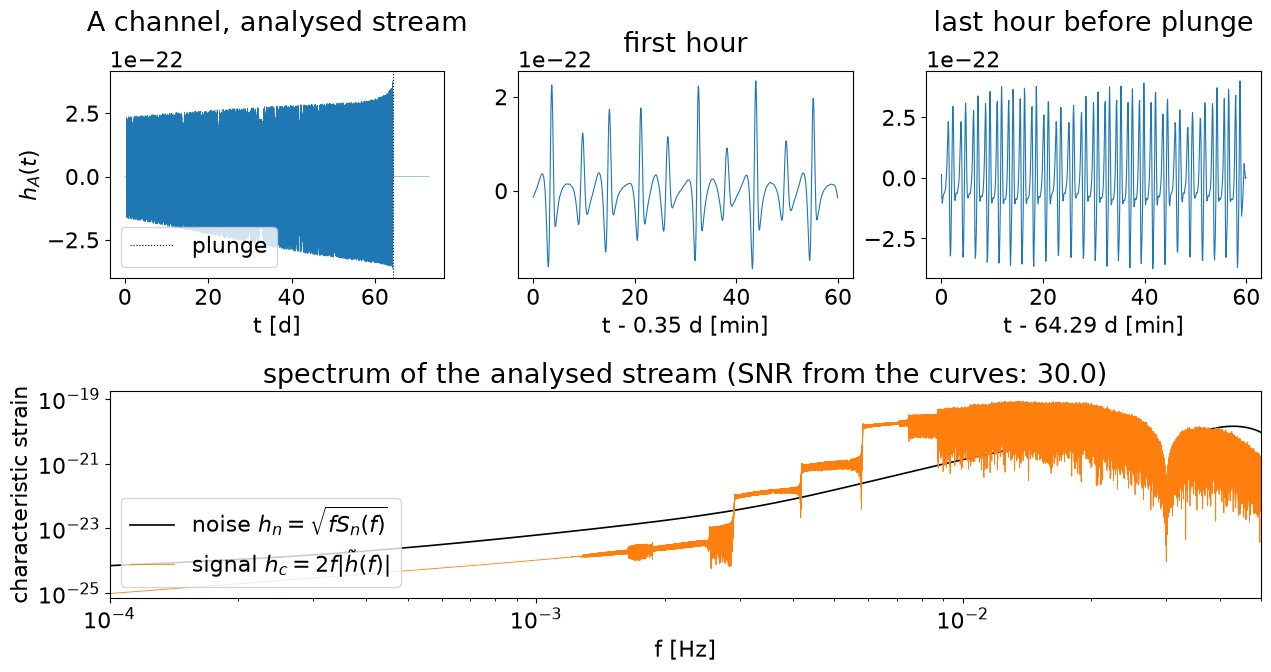

In [11]:
h_A = injection.signal[0]
t_days = injection.times / 86400
t_plunge = T_PL * YRSID_SI / 86400
fd_sig = injection.fd_data(noise=False, min_freq=1e-4, max_freq=5e-2)

fig = plt.figure(figsize=(13, 7))
gs = fig.add_gridspec(2, 3)
ax = fig.add_subplot(gs[0, 0])
step = max(1, h_A.size // 200_000)
ax.plot(t_days[::step], h_A[::step], lw=0.3)
ax.axvline(t_plunge, color="k", ls=":", lw=0.8, label="plunge")
ax.set_xlabel("t [d]"); ax.set_ylabel(r"$h_A(t)$"); ax.set_title("A channel, analysed stream", pad=14); ax.legend()
in_band = np.flatnonzero(np.abs(h_A) > 0)
hour = 1 / 24
for col, (t0, title) in enumerate(((t_days[in_band[0]], "first hour"),
                                   (min(t_plunge, t_days[in_band[-1]]) - hour, "last hour before plunge")), start=1):
    ax = fig.add_subplot(gs[0, col])
    sel = (t_days >= t0) & (t_days < t0 + hour)
    ax.plot((t_days[sel] - t0) * 1440, h_A[sel], lw=0.8)
    ax.set_xlabel(f"t - {t0:.2f} d [min]"); ax.set_title(title, pad=14)
ax = fig.add_subplot(gs[1, :])
f = fd_sig.freqs
h_c, h_n = 2 * f * np.abs(fd_sig.fd[0]), np.sqrt(f * psd(f))
ax.loglog(f, h_n, "k", lw=1.2, label=r"noise $h_n = \sqrt{f S_n(f)}$")
ax.loglog(f, h_c, "C1", lw=0.6, label=r"signal $h_c = 2f|\tilde h(f)|$")
ax.set_xlim(1e-4, 5e-2); ax.set_ylim(h_n.min() / 10, None)
ax.set_xlabel("f [Hz]"); ax.set_ylabel("characteristic strain"); ax.legend(loc="lower left")
snr_check = np.sqrt(4 * np.sum(np.abs(fd_sig.fd[0]) ** 2 / psd(f)) * fd_sig.df)
ax.set_title(f"spectrum of the analysed stream (SNR from the curves: {snr_check:.1f})")
plt.tight_layout()

## 3. Short Fourier transforms

The data are cut into $N_{\rm seg} = \lfloor T_{\rm data} / T_{\rm SFT} \rfloor$ segments starting at $t_\alpha = \alpha\,T_{\rm SFT}$.
Each is Tukey-windowed ($w_j$) and Fourier transformed:

$$
\tilde d_\alpha[k] = \Delta t \sum_{j=0}^{N_s - 1} w_j\, d(t_\alpha + j\Delta t)\, e^{-2\pi i jk/N_s},
\qquad N_s = T_{\rm SFT}/\Delta t, \qquad f_k = k/T_{\rm SFT}.
$$

`injection.sft_data(T_SFT, signal=..., noise=..., n_segments=n)` returns these as an `SFTData` for the stream of the
first $n$ segments: signal + noise (default), signal only (`noise=False`) or noise only (`signal=False`).

126 segments x 5001 bins (df = 2.0e-05 Hz)


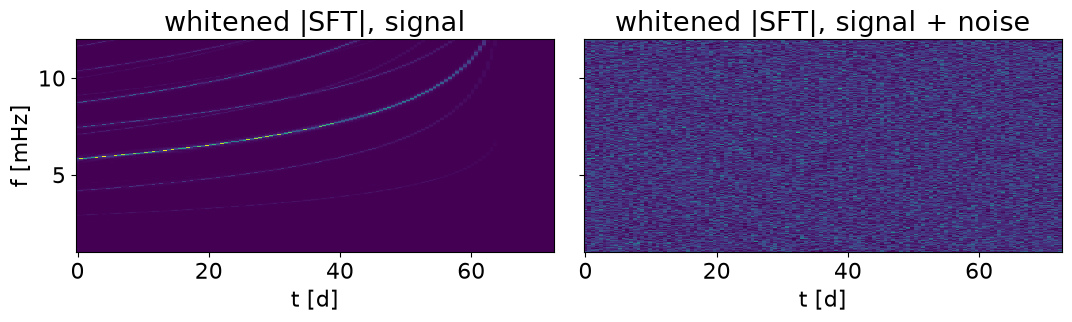

In [10]:
full = injection.sft_data(T_SFT, window_alpha=WINDOW_ALPHA)                    # h + n
signal_only = injection.sft_data(T_SFT, noise=False, window_alpha=WINDOW_ALPHA)  # h
N_SEG_TOTAL = full.n_segments
print(f"{full.n_segments} segments x {full.sfts.shape[-1]} bins (df = {1 / T_SFT:.1e} Hz)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
white = np.abs(full.sfts[0]) / np.sqrt(psd(full.freqs) * T_SFT / 2)
for a_, arr, title in ((ax[0], np.abs(signal_only.sfts[0]) / np.sqrt(psd(full.freqs) * T_SFT / 2), "signal"),
                       (ax[1], white, "signal + noise")):
    a_.pcolormesh(full.t_alpha / 86400, full.freqs * 1e3, arr.T, shading="auto")
    a_.set_title(f"whitened |SFT|, {title}")
    a_.set_xlabel("t [d]")
ax[0].set_ylabel("f [mHz]")
ax[0].set_ylim(1, 12)
plt.tight_layout()

## 4. The semi-coherent statistic

In segment $\alpha$ the dominant ($m = 2$) harmonic is modelled as a linear chirp with local frequency $f_\alpha$ and drift $\dot f_\alpha$.
Its Fourier transform is the **Fresnel kernel**

$$
K(f_0, \dot f, T) = \int_0^{T} e^{2\pi i\,(f_0 \tau + \dot f \tau^2/2)}\, d\tau
= \frac{e^{-i\pi f_0^2/\dot f}}{\sqrt{2\dot f}}\Big[\,C(u) + i S(u)\,\Big]_{u_0}^{u_1},
\quad u_0 = \frac{f_0\sqrt{2\dot f}}{\dot f},\ u_1 = u_0 + T\sqrt{2\dot f},
$$

with $C, S$ the Fresnel integrals (a Dirichlet kernel for $\dot f = 0$; $\dot f < 0$ by conjugation).
The phase-maximised matched filter over the $2P+1$ bins $k \in \lfloor f_\alpha T_{\rm SFT}\rfloor + [-P, P]$ is (paper Eq. 7)

$$
c_\alpha = \Delta f \sum_{k} \frac{\tilde d_\alpha^*[k]\; K(f_\alpha - f_k, \dot f_\alpha, T_{\rm SFT})}{S_n(f_k)},
\qquad \lvert\langle d \mid h_\alpha\rangle\rvert = 2\lvert c_\alpha \rvert,
\qquad \langle h_\alpha \mid h_\alpha\rangle = \frac{T_{\rm SFT}}{2 S_n(f_\alpha)},
$$

and the statistic (paper Eq. 6, Lorenzo's normalisation) sums the masked segments:

$$
\mathcal S = \frac12 \sum_{\alpha} w_\alpha\, \frac{\lvert\langle d \mid h_\alpha\rangle\rvert^2}{\langle h_\alpha \mid h_\alpha\rangle},
\qquad
w_\alpha = \Theta\!\left(f_\alpha - f_{\min}\right)\Theta\!\left(\dot f_\alpha - \dot f_{\min}\right)\Theta\!\left(\delta\phi_{\max} - \tfrac16\lvert\ddot f_\alpha\rvert T_{\rm SFT}^3\right).
$$

The last cut keeps segments where the neglected cubic phase is below $\delta\phi_{\max}$ (the linear chirp holds).
In noise each term is exponentially distributed with mean $2\!\int w^2/T = 2(1 - 5\alpha_w/8) = 1.75$ for $\alpha_w = 0.2$.

Below: the statistic on the injection's true frequency tracks (FEW, integrated back from plunge) for a few harmonics $m\Phi_\phi + n\Phi_r$.

In [11]:
stat_full = FresnelStatistic.for_data(full, P=P, mask=MASK, force_backend="cpu")
for m, n in ((2, 0), (2, 1), (2, -1), (3, 0), (1, 0)):
    tr = FEWHarmonicTrackModel(full.t_alpha, m=m, n=n)(SOURCE)
    print(f"harmonic (m={m}, n={n:+d}): S(data) = {stat_full.evaluate(full.sfts, tr):7.1f}   "
          f"S(signal only) = {stat_full.evaluate(signal_only.sfts, tr):7.1f}   "
          f"segments kept {int(MASK(tr, T_SFT, np).sum())}")
true_track = FEWHarmonicTrackModel(full.t_alpha, m=2, n=0)(SOURCE)
noise_mean = 1.75 * MASK(true_track, T_SFT, np).sum()
print(f"noise-only expectation on the m=2 track: ~{noise_mean:.0f}")
print(f"true track starts at f = {true_track.f[0]:.3e} Hz; F0_RANGE = {F0_RANGE}")

harmonic (m=2, n=+0): S(data) =   756.2   S(signal only) =   557.7   segments kept 110


harmonic (m=2, n=+1): S(data) =   250.0   S(signal only) =    35.3   segments kept 110


harmonic (m=2, n=-1): S(data) =   184.5   S(signal only) =    13.0   segments kept 109


harmonic (m=3, n=+0): S(data) =   241.3   S(signal only) =    69.7   segments kept 109


harmonic (m=1, n=+0): S(data) =   200.4   S(signal only) =     1.9   segments kept 110


noise-only expectation on the m=2 track: ~192
true track starts at f = 5.810e-03 Hz; F0_RANGE = (0.0005, 0.01)


## 4b. Alternative statistic: Cutler & Bustamante-Rosell's $H$

Instead of cutting the data into segments, $H$ correlates **one full-length template** $h$ with the whole stream at every
time delay $\tau_j = j\,\delta\tau$ (one inverse FFT):

$$
\rho_j = \langle d \mid h_{\tau_j}\rangle = 4\,\Delta f \sum_k \frac{\tilde d_k^*\, \tilde h_k\, e^{-2\pi i f_k \tau_j}}{S_n(f_k)},
\qquad \langle h\mid h\rangle = 1, \qquad \mathbb E_{\rm noise}\lvert\rho_j\rvert^2 = 2 .
$$

A template far from the signal overlaps it only where their f–t tracks **cross**, coherently for
$t_{\rm coh} \approx \lvert\Delta\dot f\rvert^{-1/2}$; time-slides of the template still cross, so the overlap spreads over
many consecutive delays. $H$ collects that excess power over a window of $N$ delays, normalised to unit noise variance, and maximises
over the window's start $i$ and length $N \in W$ (draft Eqs. 4, A4–A5):

$$
H = \max_{N \in W}\, \max_i \frac{\sum_{j=i}^{i+N-1}\big(\lvert\rho_j\rvert^2 - 2\big)}{\sqrt{4 N\, Q(N)}},
\qquad
Q(N) = \sum_{\lvert m\rvert < N}\Big(1 - \frac{\lvert m\rvert}{N}\Big)\lvert\langle h_0 \mid h_m\rangle\rvert^2 .
$$

$Q(N)$ corrects for the correlation of neighbouring delays (`"exact"`, per template). The draft uses its large-window limit
$R = L/K$, which only holds when the template spans a wide band (`"asymptotic"`). The matched filter
$M = \max_j \lvert\rho_j\rvert$ is the coherent comparator.

**Templates from our tracks.** The track model is unchanged (Sec. 5–6); the template follows by stationary phase:
$t(f)$ by inverting the track, $\Psi(f) = 2\pi\!\int t\,df$, amplitude $\lvert\tilde h\rvert \propto \dot f^{-1/2}$
(constant-amplitude chirp), with $\tilde h = \lvert\tilde h\rvert e^{-i\Psi}$. LISA's response is not in the template.

**Below:** how $\mathcal S$, $M$ and $H$ respond as a template is rotated away from the true track about the middle of the
stream, $f(t) \to f(t) + \epsilon\,(t - t_c)$: every such template still **crosses** the truth at $t_c$.
Each response is $(\text{value} - \mu_0)/\sigma_0$, with $\mu_0, \sigma_0$ from noise-only draws at the true template (draft Fig. 4).

FFT band (0.0003, 0.02) Hz: 124339 bins; delay step 51 s; windows (39, 83, 339, 1360) cells


eps = 0.0e+00 Hz/s:  S     31.0   M     53.9   H    112.2   (noise sigma units)
eps = 1.0e-13 Hz/s:  S     31.0   M     35.6   H    109.7   (noise sigma units)
eps = 3.0e-13 Hz/s:  S     31.1   M     20.9   H     78.6   (noise sigma units)
eps = 1.0e-12 Hz/s:  S     30.9   M      9.2   H     36.2   (noise sigma units)
eps = 3.0e-12 Hz/s:  S     27.8   M      6.4   H     22.2   (noise sigma units)
eps = 1.0e-11 Hz/s:  S     11.7   M      1.4   H     11.4   (noise sigma units)
eps = 3.0e-11 Hz/s:  S      4.8   M      1.2   H      3.1   (noise sigma units)
[   52.8 s] response computed


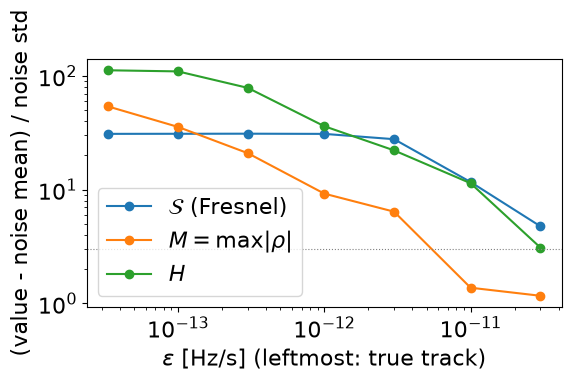

In [12]:
fd_full = injection.fd_data(min_freq=H_BAND[0], max_freq=H_BAND[1])
t_segments = full.t_alpha
H_stat = ExcessPowerStatistic.for_data(fd_full, t_segments, windows=H_WINDOWS, delay_step=H_DELAY_STEP,
                                       normalization=H_NORMALIZATION, force_backend="cpu")
M_stat = MatchedFilterStatistic.for_data(fd_full, t_segments, delay_step=H_DELAY_STEP, force_backend="cpu")
print(f"FFT band {H_BAND} Hz: {fd_full.n_bins} bins; delay step {H_stat.delay_step:.0f} s; windows {H_stat.cells} cells")

t_c = 0.5 * N_SEG_TOTAL * T_SFT
EPS = np.array([0.0, 1e-13, 3e-13, 1e-12, 3e-12, 1e-11, 3e-11])   # fdot offsets [Hz/s]


def rotated(eps):
    return Track(true_track.f + eps * (t_segments - t_c), true_track.fdot + eps, true_track.fddot)


def all_statistics(sfts_arr, fd_arr, track):
    return (float(stat_full.evaluate(sfts_arr, track)), float(M_stat.evaluate(fd_arr, track)),
            float(H_stat.evaluate(fd_arr, track)))


N_CAL = 20
cal = []
for r in range(N_CAL):
    noise_r = injection.with_noise(rng=np.random.default_rng(20_000 + r))
    cal.append(all_statistics(stat_full.prepare(noise_r.sft_data(T_SFT, signal=False, window_alpha=WINDOW_ALPHA)),
                              H_stat.prepare(noise_r.fd_data(signal=False, min_freq=H_BAND[0], max_freq=H_BAND[1])),
                              true_track))
mu0, sigma0 = np.mean(cal, axis=0), np.std(cal, axis=0, ddof=1)
sfts_arr, fd_arr = stat_full.prepare(full), H_stat.prepare(fd_full)
response = np.array([(np.array(all_statistics(sfts_arr, fd_arr, rotated(e))) - mu0) / sigma0 for e in EPS])
for e, (zs, zm, zh) in zip(EPS, response):
    print(f"eps = {e:7.1e} Hz/s:  S {zs:8.1f}   M {zm:8.1f}   H {zh:8.1f}   (noise sigma units)")
print(elapsed(), "response computed")

plt.figure(figsize=(6, 3.6))
x = np.where(EPS > 0, EPS, EPS[1] / 3)
for k, name in enumerate((r"$\mathcal{S}$ (Fresnel)", r"$M = \max|\rho|$", r"$H$")):
    plt.loglog(x, np.clip(response[:, k], 0.1, None), "o-", label=name)
plt.axhline(3, color="grey", ls=":", lw=0.8)
plt.xlabel(r"$\epsilon$ [Hz/s] (leftmost: true track)"); plt.ylabel("(value - noise mean) / noise std")
plt.legend(); plt.tight_layout()

## 5. SVD basis of frequency tracks

A bank of $N$ FEW $m = 2$ tracks $f_{i,\alpha} = f(t_\alpha;\theta_i)$, all plunging at $T_{\rm ref} = 1$ yr, on the 1-yr segment grid
$t_\alpha = \alpha T_{\rm SFT}$, $\alpha = 0, \dots, 631$ (the 632nd sample starts a partial segment past the 631 full ones and is set to zero),
is decomposed and truncated (paper Eqs. 9–10):

$$
f_{i,\alpha} = \sum_{p} U_{ip}\, S_p\, V_{p\alpha} \;\approx\; \sum_{p=1}^{K} W_{ip}\, V_{p\alpha}, \qquad W_{ip} = U_{ip} S_p .
$$

A search track is any $f_\alpha(c) = \sum_p c_p V_{p\alpha}$ with coefficients in the box $c_p \in [\ell_p, u_p]$,
$\ell_p = Q_{q}(W_{\cdot p})$, $u_p = Q_{1-q}(W_{\cdot p})$ ($u_1 = \max_i W_{i1}$), parametrised by the unit cube
$\xi \in [0,1]^K$: $c_p = \ell_p + \xi_p (u_p - \ell_p)$.

The cell builds a small bank (`N_BANK`) with the paper's priors, then checks two things against Lorenzo's file:
that his 20 modes span the new tracks, and whether each basis's box contains the injected source.

[   61.2 s] bank: 199 of 200 draws kept
new tracks on Lorenzo's 20 modes: median rel. error 7.0e-11
built    basis: source xi in [-0.33, 1.14]; modes outside the box: [np.int64(3), np.int64(7), np.int64(12), np.int64(16), np.int64(17), np.int64(19)]
Lorenzo  basis: source xi in [0.01, 1.04]; modes outside the box: [np.int64(3)]


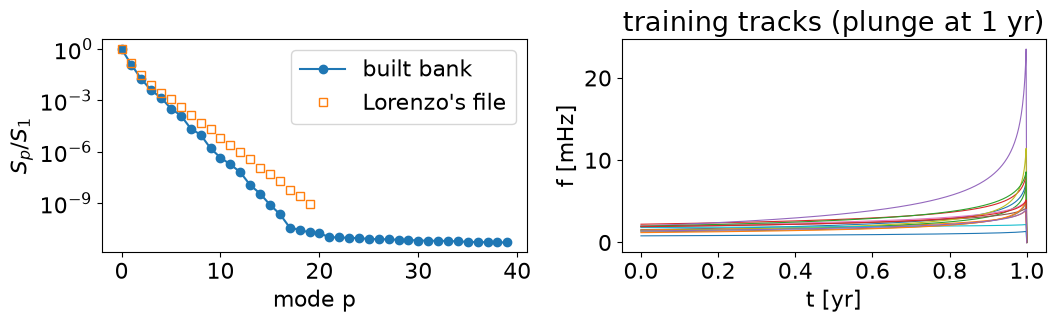

In [13]:
t_basis = np.arange(0.0, YRSID_SI, T_SFT)              # 632 samples, as V_K
bank_model = FEWHarmonicTrackModel(t_basis, m=2, n=0)
rng_bank = np.random.default_rng(BANK_SEED)
lo = np.array([BANK_PRIOR[k][0] for k in ("log10_m1", "m2", "a", "e_f")])
hi = np.array([BANK_PRIOR[k][1] for k in ("log10_m1", "m2", "a", "e_f")])
bank = []
for log10_m1, m2, a, e_f in rng_bank.uniform(lo, hi, size=(N_BANK, 4)):
    try:
        f = bank_model((10**log10_m1, m2, a, T_REF / YRSID_SI, e_f)).f
    except Exception:          # FEW cannot integrate back a full year for this draw
        continue
    if f[0] != 0.0:            # keep tracks that span the whole year
        f[-1] = 0.0            # partial 632nd segment
        bank.append(f)
bank = np.array(bank)
print(elapsed(), f"bank: {len(bank)} of {N_BANK} draws kept")

U, S_vals, Vt = np.linalg.svd(bank, full_matrices=False)
W = U[:, :N_MODES] * S_vals[:N_MODES]
lb, ub = np.quantile(W, BOX_QUANTILE, axis=0), np.quantile(W, 1 - BOX_QUANTILE, axis=0)
ub[0] = W[:, 0].max()
built_basis = SVDBasis(Vt[:N_MODES], lb, ub, S=S_vals[:N_MODES])
lorenzo_basis = SVDBasis.from_npz(BASIS_FILE)


def projection_error(tracks, basis):
    rec = (tracks @ basis.V.T) @ basis.V
    return np.linalg.norm(tracks - rec, axis=1) / np.linalg.norm(tracks, axis=1)


print(f"new tracks on Lorenzo's {lorenzo_basis.n_modes} modes: median rel. error {np.median(projection_error(bank, lorenzo_basis)):.1e}")
f_src = bank_model((M1, M2, SPIN, 1.0, E_F)).f
f_src[-1] = 0.0                                      # the source as a 1-yr basis track
for name, b in (("built", built_basis), ("Lorenzo", lorenzo_basis)):
    xi = (f_src @ b.V.T - b.lb) / (b.ub - b.lb)
    print(f"{name:8s} basis: source xi in [{xi.min():.2f}, {xi.max():.2f}]; modes outside the box: {list(np.where((xi < 0) | (xi > 1))[0])}")

basis = lorenzo_basis if BASIS_SOURCE == "lorenzo" else built_basis

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].semilogy(S_vals[:40] / S_vals[0], "o-", label="built bank")
if lorenzo_basis.S is not None:
    ax[0].semilogy(lorenzo_basis.S / lorenzo_basis.S[0], "s", mfc="none", label="Lorenzo's file")
ax[0].set_xlabel("mode p"); ax[0].set_ylabel(r"$S_p / S_1$"); ax[0].legend()
for i in np.linspace(0, len(bank) - 1, 15, dtype=int):
    ax[1].plot(t_basis / YRSID_SI, bank[i] * 1e3, lw=0.8)
ax[1].set_xlabel("t [yr]"); ax[1].set_ylabel("f [mHz]"); ax[1].set_title("training tracks (plunge at 1 yr)")
plt.tight_layout()

## 6. Plunge-time shift and data durations

The basis tracks plunge at $T_{\rm ref}$. A trial plunge time $T_{\rm pl}$ rolls the expansion by

$$
s = \operatorname{trunc}\!\left(\frac{T_{\rm pl} - T_{\rm ref}}{T_{\rm SFT}}\right),
\qquad f_\alpha \to f_{\alpha - s} \quad (\text{vacated samples} = 0),
$$

then keeps the data's segments; $\dot f_\alpha$ is the central difference of $f_\alpha$ over $t_\alpha$ and
$\ddot f_\alpha$ (for the mask) that of $\dot f_\alpha$.
The paper analyses progressively longer streams of $n_k = n_{\min} + 12k$ segments, from $T_{\min} = 0.1$ yr,
and assumes the plunge at the end of each stream: $T_{\rm pl} = n_k T_{\rm SFT}$.

In [14]:
N_MIN = int(T_MIN * YRSID_SI / T_SFT)
DURATIONS = list(range(N_MIN, N_SEG_TOTAL + 1, DURATION_STEP))
probe = SVDTrackModel(basis, full.t_alpha, T_ref=T_REF, force_backend="cpu")
print(f"{len(DURATIONS)} durations [segments]: {DURATIONS}")
print("plunge shifts:", [probe.shift_for_plunge(n * T_SFT) for n in DURATIONS])
print(f"source plunges at segment {T_PL * YRSID_SI / T_SFT:.2f}")

6 durations [segments]: [63, 75, 87, 99, 111, 123]
plunge shifts: [-568, -556, -544, -532, -520, -508]
source plunges at segment 111.16


## 7. Optimiser: Adam + differential evolution

**Initial population.** `N_INITIAL` Sobol points in the coefficient box; each track's offset is reset so it starts at
$f_0 \sim U(\texttt{F0\_RANGE})$, draws with a negative frequency are dropped, and the `N_POPULATION` best by $\mathcal S$ are kept.

**Loss.** $L(\xi) = -\mathcal S\big(f(\xi;\,s)\big)$, differentiable in $\xi$ through the Fresnel kernel (JAX).

**One iteration**, for every member $i$:

1. Adam step (Kingma & Ba) on $\nabla_\xi L$, learning rate $\eta$, clipped to $[0,1]^K$.
2. DE proposal without crossover (paper Eq. 11), with $F \sim U(F_{\min}, F_{\max})$ and the base vector the fittest member with probability $p_e$, else a random one:
$$
v_i = x_{a} + F\,(x_{b} - x_{c}), \qquad a, b, c \text{ distinct}, \ne i, \qquad v_i \to \operatorname{clip}(v_i, 0, 1).
$$
3. Greedy selection: $x_i \leftarrow v_i$ if $L(v_i) < L(x_i)$.

As in Lorenzo's loop, the selection compares the trial with the loss *before* the Adam step (`stale_selection=True`); the final population is re-scored.

In [ ]:
def make_optimizer():
    return AdamDE(
        n_steps=N_STEPS,
        adam=Adam(learning_rate=LEARNING_RATE),
        F_range=F_RANGE,
        p_elitism=P_ELITISM,
        save_every=10,
        batch_size=BATCH_SIZE,
    )


def make_data_and_statistic(stream, n_seg, signal=True, statistic=None, force_backend="jax"):
    # The data the statistic (default: STATISTIC) reads, for the first n_seg segments, and the statistic on it.
    t_alpha = np.arange(n_seg) * T_SFT
    statistic = STATISTIC if statistic is None else statistic
    if statistic not in ("fresnel", "H"):
        raise ValueError(f"unknown statistic {statistic!r}")
    if statistic == "fresnel":
        data = stream.sft_data(T_SFT, signal=signal, n_segments=n_seg, window_alpha=WINDOW_ALPHA)
        return data, FresnelStatistic.for_data(data, P=P, mask=MASK, force_backend=force_backend), t_alpha
    data = stream.fd_data(signal=signal, duration=n_seg * T_SFT, min_freq=H_BAND[0], max_freq=H_BAND[1])
    stat = ExcessPowerStatistic.for_data(data, t_alpha, windows=H_WINDOWS, delay_step=H_DELAY_STEP,
                                         normalization=H_NORMALIZATION, force_backend=force_backend)
    return data, stat, t_alpha


def search_stream(stream, n_seg, seed, signal=True, statistic=None):
    # Best track for the first n_seg segments of `stream` (an EMRIInjection with fixed noise),
    # plunge at the end of the stream; signal=False searches its noise alone.
    data, stat, t_alpha = make_data_and_statistic(stream, n_seg, signal, statistic)
    model = SVDTrackModel(basis, t_alpha, T_ref=T_REF, force_backend="jax")
    search = EMRISearch(data, stat, model, make_optimizer(), n_initial=N_INITIAL,
                        n_population=N_POPULATION, initial_kwargs={"f0_range": F0_RANGE})
    return search.run(T_pl=n_seg * T_SFT, seed=seed), data, stat

## 8. Search the injection

One optimisation per duration $n_k$; for each we record the best statistic $\mathcal S_k$ and compare it with the
statistic of the true track on the same stream.

In [15]:
injection_results = {}
for k, n_seg in enumerate(DURATIONS):
    res, data_k, stat_k = search_stream(injection, n_seg, seed=SEARCH_SEED + k)
    tt = Track(true_track.f[:n_seg], true_track.fdot[:n_seg], true_track.fddot[:n_seg])
    s_true = float(stat_k.evaluate(stat_k.prepare(data_k), tt))
    injection_results[n_seg] = dict(result=res, true_statistic=s_true)
    print(f"{elapsed()} n = {n_seg:4d} segments: best S = {res.best_statistic:8.1f}   true track S = {s_true:8.1f}")
np.savez(os.path.join(RESULTS_DIR, "injection.npz"),
         durations=DURATIONS,
         best_statistic=[injection_results[n]["result"].best_statistic for n in DURATIONS],
         true_statistic=[injection_results[n]["true_statistic"] for n in DURATIONS],
         best_x=[injection_results[n]["result"].best_x for n in DURATIONS],
         params=str(injection.params))

[   95.2 s] n =   63 segments: best S =    302.9   true track S =    525.6


[  142.7 s] n =   75 segments: best S =    391.8   true track S =    617.6


[  197.3 s] n =   87 segments: best S =    662.8   true track S =    692.0


[  258.2 s] n =   99 segments: best S =    275.7   true track S =    739.9


[  326.1 s] n =  111 segments: best S =    618.9   true track S =    756.2


[  401.8 s] n =  123 segments: best S =    639.1   true track S =    756.2


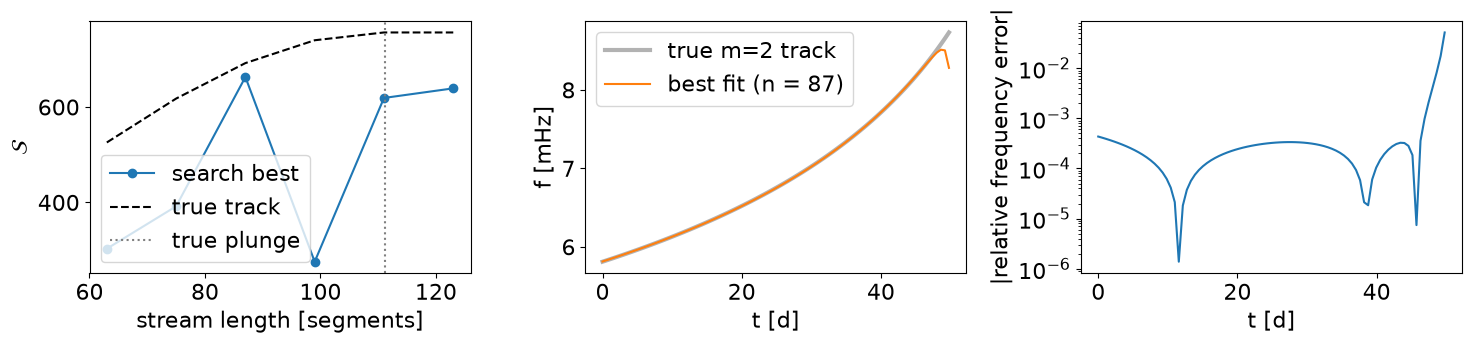

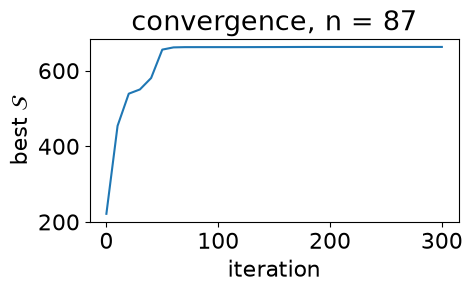

In [16]:
best_n = max(DURATIONS, key=lambda n: injection_results[n]["result"].best_statistic)
best = injection_results[best_n]["result"]
f_best = np.asarray(best.best_track.f)
t_k = full.t_alpha[:best_n]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(DURATIONS, [injection_results[n]["result"].best_statistic for n in DURATIONS], "o-", label="search best")
ax[0].plot(DURATIONS, [injection_results[n]["true_statistic"] for n in DURATIONS], "k--", label="true track")
ax[0].axvline(T_PL * YRSID_SI / T_SFT, color="grey", ls=":", label="true plunge")
ax[0].set_xlabel("stream length [segments]"); ax[0].set_ylabel(r"$\mathcal{S}$"); ax[0].legend()
ax[1].plot(t_k / 86400, true_track.f[:best_n] * 1e3, "k", lw=3, alpha=0.3, label="true m=2 track")
ax[1].plot(t_k / 86400, f_best * 1e3, "C1", label=f"best fit (n = {best_n})")
ax[1].set_xlabel("t [d]"); ax[1].set_ylabel("f [mHz]"); ax[1].legend()
ok = true_track.f[:best_n] > 0
ax[2].semilogy(t_k[ok] / 86400, np.abs(f_best[ok] / true_track.f[:best_n][ok] - 1))
ax[2].set_xlabel("t [d]"); ax[2].set_ylabel("|relative frequency error|")
plt.tight_layout()
hist = best.optimization.history
plt.figure(figsize=(5, 3.2))
plt.plot(hist["step"], [-l[0] for l in hist["loss"]])
plt.xlabel("iteration"); plt.ylabel(r"best $\mathcal{S}$"); plt.title(f"convergence, n = {best_n}")
plt.tight_layout()

## 9. Noise background, normalisation and detection

The same search runs on `N_NOISE` noise-only realisations. Because $\mathcal S$ grows with the number of segments,
the paper normalises it **per duration** with the noise-only mean and standard deviation, and the detection statistic
of a dataset is the maximum over durations:

$$
\bar{\mathcal S}_k = \frac{\mathcal S_k - \mu_k}{\sigma_k},
\qquad \Lambda = \max_k \bar{\mathcal S}_k .
$$

The noise-only $\Lambda$ follow a Gumbel distribution (extreme-value theory),
$P(\Lambda < x) = \exp\!\big[-e^{-(x - \mu_G)/\beta_G}\big]$ (paper: $\mu_G = 1.94$, $\beta_G = 0.56$).
A false-alarm probability $p_{\rm FA}$ sets the threshold

$$
\Lambda_{\rm th}(p_{\rm FA}) = \mu_G - \beta_G \ln\!\big[-\ln(1 - p_{\rm FA})\big],
$$

and a dataset is a detection when $\Lambda > \Lambda_{\rm th}$. The detection probability at a given SNR is the fraction
of injections detected (paper Eqs. 12–13). With the toy's `N_NOISE = 4` the fit only illustrates the procedure.

In [17]:
noise_statistics = np.zeros((N_NOISE, len(DURATIONS)))
for r in range(N_NOISE):
    noise_r = injection.with_noise(rng=np.random.default_rng(10_000 + r))   # a new n(t), same grid
    for k, n_seg in enumerate(DURATIONS):
        res, _, _ = search_stream(noise_r, n_seg, seed=SEARCH_SEED + 1000 * (r + 1) + k, signal=False)
        noise_statistics[r, k] = res.best_statistic
    print(f"{elapsed()} noise run {r + 1}/{N_NOISE}: max S = {noise_statistics[r].max():.1f}")
np.savez(os.path.join(RESULTS_DIR, "background.npz"), durations=DURATIONS, best_statistic=noise_statistics)

[  744.6 s] noise run 1/4: max S = 305.1


[ 1088.2 s] noise run 2/4: max S = 287.7


[ 1432.9 s] noise run 3/4: max S = 285.1


[ 1774.7 s] noise run 4/4: max S = 336.7


Gumbel fit to 4 noise maxima: location 1.03, scale 0.32   (paper: (1.94, 0.56))
p_FA = 0.5: threshold Lambda_th =   1.14   ->  injection Lambda = 72.9: DETECTED
p_FA = 0.01: threshold Lambda_th =   2.51   ->  injection Lambda = 72.9: DETECTED
p_FA = 0.0001: threshold Lambda_th =   3.99   ->  injection Lambda = 72.9: DETECTED
[ 1774.7 s] done


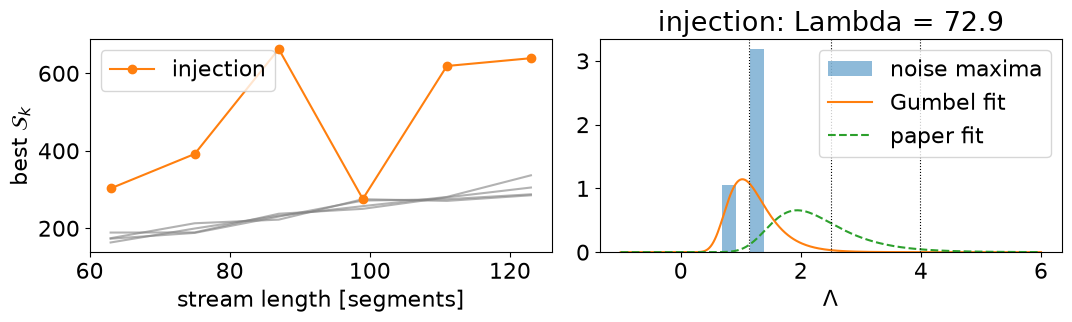

In [18]:
mu_k = noise_statistics.mean(axis=0)
sigma_k = noise_statistics.std(axis=0, ddof=1)
Lambda_noise = ((noise_statistics - mu_k) / sigma_k).max(axis=1)
S_inj = np.array([injection_results[n]["result"].best_statistic for n in DURATIONS])
Lambda_inj = ((S_inj - mu_k) / sigma_k).max()

loc, scale = stats.gumbel_r.fit(Lambda_noise)
print(f"Gumbel fit to {N_NOISE} noise maxima: location {loc:.2f}, scale {scale:.2f}   (paper: {PAPER_GUMBEL})")
for p in P_FA:
    th = stats.gumbel_r.isf(p, loc, scale)
    print(f"p_FA = {p:g}: threshold Lambda_th = {th:6.2f}   ->  injection Lambda = {Lambda_inj:.1f}: "
          f"{'DETECTED' if Lambda_inj > th else 'not detected'}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for r in range(N_NOISE):
    ax[0].plot(DURATIONS, noise_statistics[r], color="grey", alpha=0.6)
ax[0].plot(DURATIONS, S_inj, "o-C1", label="injection")
ax[0].set_xlabel("stream length [segments]"); ax[0].set_ylabel(r"best $\mathcal{S}_k$"); ax[0].legend()
x = np.linspace(min(Lambda_noise.min(), 0) - 1, max(Lambda_noise.max(), 5) + 1, 300)
ax[1].hist(Lambda_noise, bins=max(N_NOISE // 5, 3), density=True, alpha=0.5, label="noise maxima")
ax[1].plot(x, stats.gumbel_r.pdf(x, loc, scale), label="Gumbel fit")
ax[1].plot(x, stats.gumbel_r.pdf(x, *PAPER_GUMBEL), "--", label="paper fit")
for p in P_FA:
    ax[1].axvline(stats.gumbel_r.isf(p, loc, scale), color="k", ls=":", lw=0.8)
ax[1].set_xlabel(r"$\Lambda$"); ax[1].legend()
ax[1].set_title(f"injection: Lambda = {Lambda_inj:.1f}")
plt.tight_layout()
print(elapsed(), "done")

## 10. Which statistic is better? A paired comparison

Each statistic in `COMPARE_STATISTICS` runs the full search (Secs. 6–8: every duration, plunge at the end of the stream) on
the same injections and noise, with the same optimiser and seeds; only the objective changes (as in the CB-R draft, Sec. V).
Two questions, per SNR:

* **Localisation.** At the duration $k^\star$ where the normalised statistic peaks, does the best track follow the true
  m=2 track? The agreement is the fraction of in-band segments with
  $\lvert f^{\rm best}_\alpha - f^{\rm true}_\alpha\rvert < $ `LOC_TOL_BINS`$/T_{\rm SFT}$; the run is localised when it
  reaches `LOC_FRACTION`.
* **Detection.** With each statistic's own noise background (`COMPARE_N_NOISE` noise-only searches),
  $\Lambda = \max_k (X_k - \mu_k)/\sigma_k$ (Sec. 9) against the Gumbel threshold at `COMPARE_P_FA`.

Thick lines count single runs; dashed lines count an injection as found when any of its `COMPARE_N_SEEDS` restarts is
(best-of-seeds, which would need its own background for a false-alarm rate). Results are saved per statistic in
`RESULTS_DIR/compare_<statistic>.npz`; with `COMPARE_RESUME` a rerun skips finished statistics.

**Cost.** `len(COMPARE_STATISTICS)` × (sources × SNRs × seeds + noise sets) × durations optimisations (printed below).
A Fresnel optimisation of the toy takes ~1 min on an M3 Pro; time one `"H"` run before a long campaign.
$H$ reads a coherent FFT over `H_BAND` ($\approx 6\times10^5$ bins for 1 yr), so set `BATCH_SIZE` (e.g. 32) for long data.

In [ ]:
true_model = FEWHarmonicTrackModel(full.t_alpha, m=2, n=0)


def draw_sources(n, seed):
    # Table 1 sources, each plunging at the end of a random duration of the grid, starting inside F0_RANGE.
    rng = np.random.default_rng(seed)
    lo_p = np.array([BANK_PRIOR[k][0] for k in ("log10_m1", "m2", "a", "e_f")])
    hi_p = np.array([BANK_PRIOR[k][1] for k in ("log10_m1", "m2", "a", "e_f")])
    sources = []
    while len(sources) < n:
        log10_m1, m2, a, e_f = rng.uniform(lo_p, hi_p)
        n_pl = int(rng.choice(DURATIONS))
        T_pl = (YRSID_SI + probe.shift_for_plunge(n_pl * T_SFT) * T_SFT) / YRSID_SI
        params = (10**log10_m1, m2, a, T_pl, e_f)
        try:
            f = true_model(params).f
        except Exception:      # FEW cannot integrate this draw back to t = 0
            continue
        if F0_RANGE[0] <= f[0] <= F0_RANGE[1]:
            sources.append(params)
    return sources


def agreement(best_f, true_f):
    # Fraction of the true track's in-band segments that the best track follows within LOC_TOL_BINS bins.
    valid = true_f > MASK.f_min
    if not valid.any():
        return 0.0
    return float(np.mean(np.abs(best_f[valid] - true_f[valid]) < LOC_TOL_BINS / T_SFT))


compare_sources = draw_sources(COMPARE_N_SOURCES, COMPARE_SEED)
for i, src in enumerate(compare_sources):
    print(f"source {i}: m1 = {src[0]:.3g}, m2 = {src[1]:.1f}, a = {src[2]:.2f}, T_pl = {src[3]:.3f} yr, e_f = {src[4]:.3f}")
n_runs = len(COMPARE_STATISTICS) * (COMPARE_N_SOURCES * len(COMPARE_SNRS) * COMPARE_N_SEEDS + COMPARE_N_NOISE) * len(DURATIONS)
print(f"{n_runs} optimisations in total")

In [ ]:
def run_comparison(statistic, sources):
    path = os.path.join(RESULTS_DIR, f"compare_{statistic}.npz")
    if COMPARE_RESUME and os.path.exists(path):
        print(f"[{statistic}] loaded {path}")
        return dict(np.load(path))
    shape = (len(sources), len(COMPARE_SNRS), COMPARE_N_SEEDS, len(DURATIONS))
    X, agree = np.zeros(shape), np.zeros(shape)
    for i, src in enumerate(sources):
        noise_i = injection.draw_noise(rng=np.random.default_rng(1_000 * COMPARE_SEED + i))   # paired
        true_f = true_model(src).f
        for j, snr in enumerate(COMPARE_SNRS):
            inj = injector(src, snr, psd, T_data=T_DATA, rng=np.random.default_rng(COMPARE_SEED + i))
            inj = inj.with_noise(noise=noise_i)
            for s in range(COMPARE_N_SEEDS):
                for k, n_seg in enumerate(DURATIONS):
                    res, _, _ = search_stream(inj, n_seg, seed=100 * s + k, statistic=statistic)
                    X[i, j, s, k] = res.best_statistic
                    agree[i, j, s, k] = agreement(np.asarray(res.best_track.f), true_f[:n_seg])
            print(f"{elapsed()} [{statistic}] source {i + 1}/{len(sources)}, SNR {snr:g}: "
                  f"best per duration {np.round(X[i, j].max(axis=0), 1)}")
    background = np.zeros((COMPARE_N_NOISE, len(DURATIONS)))
    for r in range(COMPARE_N_NOISE):
        noise_r = injection.with_noise(rng=np.random.default_rng(30_000 + r))
        for k, n_seg in enumerate(DURATIONS):
            res, _, _ = search_stream(noise_r, n_seg, seed=5_000 + 100 * r + k, signal=False, statistic=statistic)
            background[r, k] = res.best_statistic
        print(f"{elapsed()} [{statistic}] noise set {r + 1}/{COMPARE_N_NOISE}: max {background[r].max():.1f}")
    out = dict(X=X, agree=agree, background=background, durations=np.asarray(DURATIONS),
               snrs=np.asarray(COMPARE_SNRS), sources=np.asarray(sources))
    np.savez(path, **out)
    return out


comparison = {name: run_comparison(name, compare_sources) for name in COMPARE_STATISTICS}

In [ ]:
summary = {}
for name, out in comparison.items():
    B = out["background"]
    mu, sd = B.mean(axis=0), B.std(axis=0, ddof=1)
    Z = (out["X"] - mu) / sd                               # (source, SNR, seed, duration)
    Lam = Z.max(axis=-1)
    k_star = Z.argmax(axis=-1)
    agree_star = np.take_along_axis(out["agree"], k_star[..., None], axis=-1)[..., 0]
    loc, scale = stats.gumbel_r.fit(((B - mu) / sd).max(axis=1))
    threshold = stats.gumbel_r.isf(COMPARE_P_FA, loc, scale)
    detected, localised = Lam > threshold, agree_star >= LOC_FRACTION
    summary[name] = dict(detect=detected.mean(axis=(0, 2)), localise=localised.mean(axis=(0, 2)),
                         detect_any=detected.any(axis=2).mean(axis=0), localise_any=localised.any(axis=2).mean(axis=0),
                         threshold=threshold, agree=agree_star.mean(axis=(0, 2)))

print(f"{'statistic':10s} {'SNR':>5s} {'detected':>9s} {'localised':>10s} {'mean agreement':>15s}   threshold")
for name, r in summary.items():
    for j, snr in enumerate(COMPARE_SNRS):
        print(f"{name:10s} {snr:5g} {r['detect'][j]:9.2f} {r['localise'][j]:10.2f} {r['agree'][j]:15.2f}   {r['threshold']:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for c, (name, r) in enumerate(summary.items()):
    for a_, key, title in ((ax[0], "detect", f"detected (p_FA = {COMPARE_P_FA:g})"), (ax[1], "localise", "localised")):
        a_.plot(COMPARE_SNRS, r[key], "o-", color=f"C{c}", lw=2, label=name)
        a_.plot(COMPARE_SNRS, r[key + "_any"], "--", color=f"C{c}", label=f"{name}, best of {COMPARE_N_SEEDS}")
        a_.set_title(title); a_.set_xlabel("injected SNR")
ax[0].set_ylabel("fraction of runs"); ax[0].set_ylim(-0.05, 1.05); ax[1].legend()
plt.tight_layout()

## 11. Producing the paper's results

1. Switch every input above to its `# PAPER:` value (1 yr data, 48 durations, 1024 → 512 members, 525 iterations,
   $f_0 \in [5\times10^{-4}, 10^{-2}]$ Hz, `N_NOISE = 100`); on a 64 GB laptop `BATCH_SIZE = 256` or `None`.
2. Background: run Sec. 9 once (100 noise realisations). Keep `mu_k`, `sigma_k` and the Gumbel fit.
3. Injections: for each SNR in 20, 25, 30, 35, 40 and 100 draws of the Table 1 priors (Sec. 1c, `SOURCE_SEED` = draw index),
   run Secs. 2–8 and record $\Lambda$; the detection probability is the fraction above $\Lambda_{\rm th}(p_{\rm FA})$.
4. Budget: one full search $\approx$ 18 h on an M3 Pro (measured per-iteration cost, `BATCH_SIZE = 128`); scale by your machine's
   measured iteration time. The full set (600 searches) is a cluster job.

Not included: the paper's follow-up (simulation-based inference, scipy DE on the physical parameters, eryn MCMC).